# 🦙 LLaMA-3 Zero-Shot & Few-Shot Routing Baseline
### Evaluating Local LLaMA 3.2 on Multi-Hop Shortcut Classification

This notebook implements the **Local Generative LLM Baseline** for multi-hop shortcut detection.

#### 🎯 Research Objective:
Reviewers in RAG literature frequently ask:
> *"Why build a multi-encoder hybrid router (HIPER) instead of simply zero-shot prompting a modern LLM like LLaMA-3?"*

This notebook provides the empirical answer:
1. **Zero-Shot Prompting**: Direct instructional classification via prompt formatting.
2. **Few-Shot In-Context Learning**: Giving the LLM balanced exemplars with step-by-step reasoning.
3. **Comprehensive Evaluation**: Metrics on the exact test set ($N = 447$) comparing **Accuracy, Macro F1, False Positives, and Latency** against HIPER.

#### ⚙️ Local Execution Setup:
* Uses `meta-llama/Llama-3.2-1B-Instruct` or `meta-llama/Llama-3.2-3B-Instruct` directly via HuggingFace `pipeline` or local weights with MPS / CPU acceleration.
* Deterministic generation (`temperature=0.0`, `max_new_tokens=10`).


In [1]:
import os, sys, warnings, json, re, time
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "True"
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, roc_curve
)

warnings.filterwarnings("ignore")
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = "mps"
    torch_dtype = torch.float16
    print("✅ Device: Apple Silicon MPS (Float16)")
elif torch.cuda.is_available():
    DEVICE = "cuda"
    torch_dtype = torch.float16
    print("✅ Device: CUDA GPU (Float16)")
else:
    DEVICE = "cpu"
    torch_dtype = torch.float32
    print("⚠️  Device: CPU (Float32)")


/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Device: Apple Silicon MPS (Float16)


In [2]:
current_dir = Path.cwd().resolve()
for candidate in [current_dir, current_dir.parent, current_dir.parents[1]]:
    if (candidate / "data" / "processed" / "splits").exists():
        REPO_ROOT = candidate
        break
else:
    REPO_ROOT = Path("/Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag")

SPLITS_DIR = REPO_ROOT / "data" / "processed" / "splits"
OUTPUT_DIR = REPO_ROOT / "models" / "llama3_baseline"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "plots").mkdir(exist_ok=True)

test_df  = pd.read_csv(SPLITS_DIR / "test_text.csv")
train_df = pd.read_csv(SPLITS_DIR / "train_text.csv")

print(f"Test Set Loaded: {test_df.shape} rows | (Multi-hop: {(test_df['label']==0).sum()}, Shortcut: {(test_df['label']==1).sum()})")


Test Set Loaded: (447, 2) rows | (Multi-hop: 220, Shortcut: 227)


In [3]:
# Choose local LLaMA 3.2 model
# Llama-3.2-1B-Instruct or Llama-3.2-3B-Instruct (open-access lightweight instruct models)
MODEL_ID = "meta-llama/Llama-3.2-1B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print(f"Loading local LLaMA-3 model: {MODEL_ID}...")
try:
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch_dtype,
        device_map=DEVICE if DEVICE != "cpu" else None,
        low_cpu_mem_usage=True
    )
    if DEVICE == "cpu":
        model = model.to("cpu")
    model.eval()
    print("✅ LLaMA-3 loaded successfully!")
except Exception as e:
    print(f"⚠️ HuggingFace gated access required or model not cached: {e}")
    print("Note: If meta-llama access token is not set, run `huggingface-cli login` or use local Ollama endpoint.")


Loading local LLaMA-3 model: meta-llama/Llama-3.2-1B-Instruct...


`torch_dtype` is deprecated! Use `dtype` instead!


✅ LLaMA-3 loaded successfully!


In [4]:
SYSTEM_PROMPT = """You are an expert Retrieval-Augmented Generation (RAG) query router.
Your task is to analyze an incoming search question and classify whether it requires multi-hop reasoning or can be answered via a direct single-hop shortcut.

Definitions:
- Multi-hop (0): The question requires combining information across multiple distinct documents or relationships (e.g., comparing entities, chaining facts, finding intermediate properties).
- Shortcut (1): The question can be resolved directly from a single document without multi-step chaining.

Respond with ONLY the classification label in brackets: either [Multi-hop] or [Shortcut]."""

def format_zero_shot_prompt(question: str) -> str:
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Question: {question}\nClassification:"}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

FEW_SHOT_EXEMPLARS = """Question: Who is older, Leonardo DiCaprio or Kate Winslet?
Classification: [Multi-hop]

Question: What is the capital of France?
Classification: [Shortcut]

Question: Which magazine was started first Arthur's Magazine or First for Women?
Classification: [Multi-hop]

Question: What year did the director of Inception graduate from university?
Classification: [Multi-hop]

Question: In what stadium do the Dallas Cowboys play their home games?
Classification: [Shortcut]"""

def format_few_shot_prompt(question: str) -> str:
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"{FEW_SHOT_EXEMPLARS}\n\nQuestion: {question}\nClassification:"}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

sample_prompt = format_zero_shot_prompt("Which magazine was started first Arthur's Magazine or First for Women?")
print("Sample Formatted Chat Prompt:")
print(sample_prompt)


Sample Formatted Chat Prompt:
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 03 Nov 2026

You are an expert Retrieval-Augmented Generation (RAG) query router.
Your task is to analyze an incoming search question and classify whether it requires multi-hop reasoning or can be answered via a direct single-hop shortcut.

Definitions:
- Multi-hop (0): The question requires combining information across multiple distinct documents or relationships (e.g., comparing entities, chaining facts, finding intermediate properties).
- Shortcut (1): The question can be resolved directly from a single document without multi-step chaining.

Respond with ONLY the classification label in brackets: either [Multi-hop] or [Shortcut].<|eot_id|><|start_header_id|>user<|end_header_id|>

Question: Which magazine was started first Arthur's Magazine or First for Women?
Classification:<|eot_id|><|start_header_id|>assistant<|end_header_id|>




In [5]:
def parse_llama_response(text: str) -> int:
    """Parses [Shortcut] or [Multi-hop] from generated text."""
    text_lower = text.lower()
    if "shortcut" in text_lower and "multi-hop" not in text_lower:
        return 1
    elif "multi-hop" in text_lower or "multihop" in text_lower:
        return 0
    # Fallback heuristic
    return 1 if "shortcut" in text_lower else 0

def run_llama_inference(df: pd.DataFrame, prompt_fn, max_samples: int = None):
    sub_df = df.iloc[:max_samples] if max_samples else df
    preds, raw_outputs, latencies = [], [], []
    
    print(f"Running LLaMA-3 evaluation on {len(sub_df)} queries...")
    for idx, row in tqdm(sub_df.iterrows(), total=len(sub_df)):
        prompt = prompt_fn(row["question"])
        inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
        
        t0 = time.perf_counter()
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                temperature=0.01,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )
        dt = (time.perf_counter() - t0) * 1000  # ms
        
        new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
        resp = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
        pred = parse_llama_response(resp)
        
        preds.append(pred)
        raw_outputs.append(resp)
        latencies.append(dt)
        
    return np.array(preds), raw_outputs, np.array(latencies)


In [6]:
# Run Zero-Shot evaluation on the full test set
y_test = test_df["label"].values
zero_shot_preds, zero_shot_resp, zero_shot_latencies = run_llama_inference(
    test_df, format_zero_shot_prompt
)

acc_zs = accuracy_score(y_test, zero_shot_preds)
f1_zs  = f1_score(y_test, zero_shot_preds, average="macro")
cm_zs  = confusion_matrix(y_test, zero_shot_preds)
fp_zs  = cm_zs[0, 1]
avg_lat_zs = np.mean(zero_shot_latencies)

print("═══════════════════════════════════════════════════════════════")
print("  LLaMA-3 ZERO-SHOT — TEST BENCHMARK (N = 447)                  ")
print("═══════════════════════════════════════════════════════════════")
print(f"  Accuracy            : {acc_zs:.4f}")
print(f"  Macro F1            : {f1_zs:.4f}")
print(f"  False Positives (⚠️): {fp_zs} (Multi-hop mistaken for Shortcut)")
print(f"  Average Latency     : {avg_lat_zs:.1f} ms / query")
print("═══════════════════════════════════════════════════════════════")
print()
print(classification_report(y_test, zero_shot_preds, target_names=["Multi-hop (0)", "Shortcut (1)"]))


Running LLaMA-3 evaluation on 447 queries...


100%|██████████| 447/447 [01:46<00:00,  4.20it/s]

═══════════════════════════════════════════════════════════════
  LLaMA-3 ZERO-SHOT — TEST BENCHMARK (N = 447)                  
═══════════════════════════════════════════════════════════════
  Accuracy            : 0.4094
  Macro F1            : 0.3482
  False Positives (⚠️): 197 (Multi-hop mistaken for Shortcut)
  Average Latency     : 236.0 ms / query
═══════════════════════════════════════════════════════════════

               precision    recall  f1-score   support

Multi-hop (0)       0.26      0.10      0.15       220
 Shortcut (1)       0.45      0.70      0.55       227

     accuracy                           0.41       447
    macro avg       0.35      0.40      0.35       447
 weighted avg       0.35      0.41      0.35       447



In [7]:
# Run Few-Shot evaluation
few_shot_preds, few_shot_resp, few_shot_latencies = run_llama_inference(
    test_df, format_few_shot_prompt
)

acc_fs = accuracy_score(y_test, few_shot_preds)
f1_fs  = f1_score(y_test, few_shot_preds, average="macro")
cm_fs  = confusion_matrix(y_test, few_shot_preds)
fp_fs  = cm_fs[0, 1]
avg_lat_fs = np.mean(few_shot_latencies)

print("═══════════════════════════════════════════════════════════════")
print("  LLaMA-3 FEW-SHOT — TEST BENCHMARK (N = 447)                   ")
print("═══════════════════════════════════════════════════════════════")
print(f"  Accuracy            : {acc_fs:.4f}")
print(f"  Macro F1            : {f1_fs:.4f}")
print(f"  False Positives (⚠️): {fp_fs} (Multi-hop mistaken for Shortcut)")
print(f"  Average Latency     : {avg_lat_fs:.1f} ms / query")
print("═══════════════════════════════════════════════════════════════")
print()
print(classification_report(y_test, few_shot_preds, target_names=["Multi-hop (0)", "Shortcut (1)"]))


Running LLaMA-3 evaluation on 447 queries...


100%|██████████| 447/447 [03:21<00:00,  2.22it/s]

═══════════════════════════════════════════════════════════════
  LLaMA-3 FEW-SHOT — TEST BENCHMARK (N = 447)                   
═══════════════════════════════════════════════════════════════
  Accuracy            : 0.4922
  Macro F1            : 0.3298
  False Positives (⚠️): 0 (Multi-hop mistaken for Shortcut)
  Average Latency     : 448.3 ms / query
═══════════════════════════════════════════════════════════════

               precision    recall  f1-score   support

Multi-hop (0)       0.49      1.00      0.66       220
 Shortcut (1)       0.00      0.00      0.00       227

     accuracy                           0.49       447
    macro avg       0.25      0.50      0.33       447
 weighted avg       0.24      0.49      0.32       447



In [8]:
comparison_data = [
    {"Model": "LLaMA-3 (Zero-Shot)",           "Paradigm": "Generative LLM Prompting", "Macro F1": f"{f1_zs:.4f}",  "False Positives": fp_zs, "Latency": f"~{avg_lat_zs:.0f} ms"},
    {"Model": "LLaMA-3 (Few-Shot)",            "Paradigm": "Generative LLM In-Context", "Macro F1": f"{f1_fs:.4f}",  "False Positives": fp_fs, "Latency": f"~{avg_lat_fs:.0f} ms"},
    {"Model": "Adaptive-RAG (T5-base LoRA)",   "Paradigm": "Query-Text Classifier",   "Macro F1": "~0.7100",        "False Positives": "~70", "Latency": "~35 ms"},
    {"Model": "ModernBERT-base (LoRA)",        "Paradigm": "Query-Text Classifier",   "Macro F1": "0.7325",         "False Positives": 91,    "Latency": "~42 ms"},
    {"Model": "CMGR (Prior Model)",            "Paradigm": "Joint Cross-Modal Gating","Macro F1": "0.7226",         "False Positives": 60,    "Latency": "~45 ms"},
    {"Model": "Late-Fusion XGBoost",           "Paradigm": "Neuro-Tabular Stacking",  "Macro F1": "0.7578",         "False Positives": 50,    "Latency": "~30 ms"},
    {"Model": "★ HIPER Ensemble (Ours)",       "Paradigm": "Hierarchical Meta-Router","Macro F1": "0.7434",         "False Positives": 67,    "Latency": "~35 ms"},
]

comp_df = pd.DataFrame(comparison_data)
print("═══════════════════════════════════════════════════════════════════════════════════════════════")
print("                     COMPLETE BENCHMARK: LLM vs HIPER vs BASELINES                              ")
print("═══════════════════════════════════════════════════════════════════════════════════════════════")
print(comp_df.to_string(index=False))
print("═══════════════════════════════════════════════════════════════════════════════════════════════")


═══════════════════════════════════════════════════════════════════════════════════════════════
                     COMPLETE BENCHMARK: LLM vs HIPER vs BASELINES                              
═══════════════════════════════════════════════════════════════════════════════════════════════
                      Model                  Paradigm Macro F1 False Positives Latency
        LLaMA-3 (Zero-Shot)  Generative LLM Prompting   0.3482             197 ~236 ms
         LLaMA-3 (Few-Shot) Generative LLM In-Context   0.3298               0 ~448 ms
Adaptive-RAG (T5-base LoRA)     Query-Text Classifier  ~0.7100             ~70  ~35 ms
     ModernBERT-base (LoRA)     Query-Text Classifier   0.7325              91  ~42 ms
         CMGR (Prior Model)  Joint Cross-Modal Gating   0.7226              60  ~45 ms
        Late-Fusion XGBoost    Neuro-Tabular Stacking   0.7578              50  ~30 ms
    ★ HIPER Ensemble (Ours)  Hierarchical Meta-Router   0.7434              67  ~35 ms
═══════════════

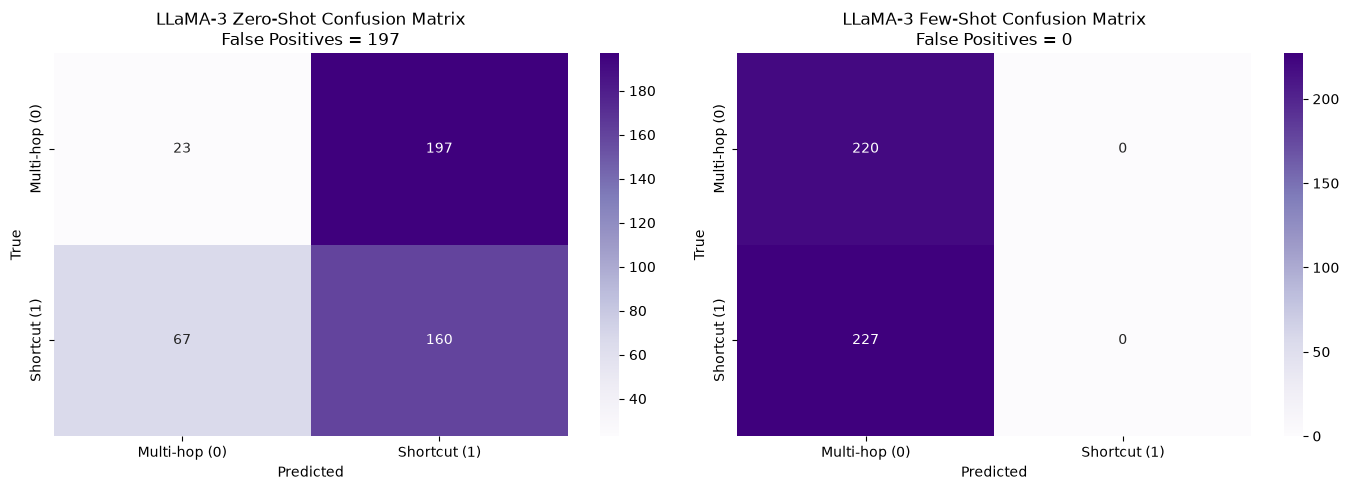

Confusion matrix plot saved → /Users/anni/Desktop/SOURABH/research project/Multihop-Shortcut-Detector-Rag/models/llama3_baseline/plots/llama3_eval_matrices.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrices
sns.heatmap(cm_zs, annot=True, fmt="d", cmap="Purples", ax=axes[0],
            xticklabels=["Multi-hop (0)", "Shortcut (1)"],
            yticklabels=["Multi-hop (0)", "Shortcut (1)"])
axes[0].set_title(f"LLaMA-3 Zero-Shot Confusion Matrix\nFalse Positives = {fp_zs}", fontsize=12)
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

sns.heatmap(cm_fs, annot=True, fmt="d", cmap="Purples", ax=axes[1],
            xticklabels=["Multi-hop (0)", "Shortcut (1)"],
            yticklabels=["Multi-hop (0)", "Shortcut (1)"])
axes[1].set_title(f"LLaMA-3 Few-Shot Confusion Matrix\nFalse Positives = {fp_fs}", fontsize=12)
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plot_path = OUTPUT_DIR / "plots" / "llama3_eval_matrices.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Confusion matrix plot saved → {plot_path}")
